# Foldseek decoy simulation

For each query structure we generate decoys that keep the query's composition but
destroy its structure: Foldseek `structureshuffle` resamples the **3Di** and the
**amino-acid** strings with two **independent first-order Markov chains**. Each decoy is
searched against SCOP40, and its best hit is a draw from the null distribution. A
calibrated significance measure therefore gives Uniform(0, 1) values, which fall on the
diagonal of a log-log QQ plot. Foldseek's own E-values do not; SG p-values do.

| Step | What | Output in `results/simulation/foldseek/<tag>/` |
|---|---|---|
| 1 | query DB + decoys (`createdb`, `structureshuffle`) | `db/query`, `db/decoy` |
| 2 | search decoys vs SCOP40 (`easy-search`) | `search_t<T>_g<G>.tsv` |
| 3 | best hit per decoy, by bit score and by E-value | `sorted_t<T>_g<G>.tsv`, `sorted_evalue_t<T>_g<G>.tsv` |
| 4 | SG p-value per decoy | `sgpvalue_t<T>_g<G>.tsv` |
| 5 | QQ plots (E-value and SG p-value) | `qqplot_Evalue_t<T>_g<G>.pdf`, `qqplot_SGPvalue_t<T>_g<G>.pdf` |

`T` is the alignment type (0 = 3Di, 2 = 3Di+AA) and `G` the gap-open cost.

**Before you start:** run this notebook from `tutorial/`. From Zenodo, unpack these at
the repository root:
- `results_simulation.tar.gz` gives `results/simulation/`, the paper's decoy results. With
  it, the notebook goes straight to the plots.
- To rerun the decoy searches, you also need `data_simulation.tar.gz` (query structures
  and SCOP40 targets in `data/simulation/`) and the tools from `bash scripts/build.sh`.
  With 200,000 decoys, one query takes about 17 min on 32 threads for both alignment types.

With `USE_CACHED = True` (the default), every step whose output already exists is skipped.
With the Zenodo results unpacked, the notebook only draws the plots. The table after the
parameters shows what will be reused and what will be computed. Set `USE_CACHED = False`
to recompute everything.

## Parameters

In [1]:
from pathlib import Path
import os
if not Path('scripts/build.sh').exists():   # opened from tutorial/: work from the repository root
    os.chdir('..')
ROOT = Path('.')                            # all paths below are relative to the repository root

FOLDSEEK  = ROOT / 'bin/foldseek'
TARGET_DB = ROOT / 'data/simulation/scop40_foldseek/scop_40'
LOOKUP    = ROOT / 'data/lookup/m50.txt'
OUTROOT   = ROOT / 'results/simulation/foldseek'

# (query structure, tag, amino-acid length): the five SCOP domains used in the paper
QUERIES = [
    ('data/simulation/queries/d1zavu1.ent', 'd1za_30',  30),    # a.108.1.1
    ('data/simulation/queries/d1stza1.ent', 'd1st_87',  87),    # a.4.5.51
    ('data/simulation/queries/d2ao9a1.ent', 'd2ao_120', 120),   # a.4.1.17
    ('data/simulation/queries/d1ku9a_.ent', 'd1ku_151', 151),   # a.4.5.36
    ('data/simulation/queries/d2uy2a_.ent', 'd2uy_288', 288),   # c.1.8.0
]

NUM_SHUFFLES   = 200000   # decoys per query
SEED           = 1         # structureshuffle seed (same seed -> identical decoys)
ALN_TYPES      = [0, 2]    # 0 = 3Di only, 2 = 3Di+AA
GAP_OPEN       = 2
COMP_BIAS_CORR = 0
THREADS        = 32
N_NULL         = 50        # null sample size; must match LOOKUP (m50 -> 50)
SG_SEED        = 0         # seed for drawing the null samples in step 4
USE_CACHED     = True      # reuse outputs already in OUTROOT (e.g. the Zenodo results); False = recompute all

In [2]:
import csv
import os
import subprocess
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import display

matplotlib.rcParams['pdf.fonttype'] = 42   # keep PDF text as text
matplotlib.rcParams['ps.fonttype'] = 42


def run(cmd, log=None):
    """Run an external command; stream nothing, keep its output in `log`, fail loudly."""
    cmd = [str(c) for c in cmd]
    print('$', ' '.join(cmd))
    with open(log, 'w') if log else open(os.devnull, 'w') as fh:
        subprocess.run(cmd, check=True, stdout=fh, stderr=subprocess.STDOUT)


def needs(path):
    """True if `path` must be (re)computed: USE_CACHED is off, or the file is missing/empty."""
    return not USE_CACHED or not Path(path).exists() or Path(path).stat().st_size == 0


def cached(path):
    print(f'cached: {path}')


### What will run

In [3]:
def sfx(t):
    return f't{t}_g{GAP_OPEN}'


def search_needed(tag, t):
    """The decoy search runs only if neither it nor its best-hit tables are cached."""
    out = OUTROOT / tag
    return needs(out / f'search_{sfx(t)}.tsv') and (
        needs(out / f'sorted_{sfx(t)}.tsv') or needs(out / f'sorted_evalue_{sfx(t)}.tsv'))


rows = []
for _, tag, _ in QUERIES:
    out = OUTROOT / tag
    for t in ALN_TYPES:
        have = {step: not needs(out / f.format(sfx(t))) for step, f in
                [('decoy search', 'search_{}.tsv'), ('best hits (bits)', 'sorted_{}.tsv'),
                 ('best hits (E-value)', 'sorted_evalue_{}.tsv'), ('SG p-values', 'sgpvalue_{}.tsv')]}
        todo = ('decoys + search + analysis' if search_needed(tag, t)
                else 'plots only' if all(list(have.values())[1:]) else 'analysis')
        rows.append({'query': tag, 'aln_type': t, **{k: 'cached' if v else '-' for k, v in have.items()},
                     'will run': todo})
pd.DataFrame(rows)

,query,aln_type,decoy search,best hits (bits),best hits (E-value),SG p-values,will run
0,d1za_30,0,cached,cached,cached,cached,plots only
1,d1za_30,2,cached,cached,cached,cached,plots only
2,d1st_87,0,cached,cached,cached,cached,plots only
3,d1st_87,2,cached,cached,cached,cached,plots only
4,d2ao_120,0,cached,cached,cached,cached,plots only
5,d2ao_120,2,cached,cached,cached,cached,plots only
6,d1ku_151,0,cached,cached,cached,cached,plots only
7,d1ku_151,2,cached,cached,cached,cached,plots only
8,d2uy_288,0,cached,cached,cached,cached,plots only
9,d2uy_288,2,cached,cached,cached,cached,plots only


## 1. Query DB and decoys

`structureshuffle` writes `NUM_SHUFFLES` decoys named `<query>_markovtog<N>`. With a
fixed `SEED`, the decoy DB is identical across runs.

In [4]:
for structure, tag, _ in QUERIES:
    if not any(search_needed(tag, t) for t in ALN_TYPES):
        print(f'{tag}: decoys not needed (search results cached)')
        continue
    db = OUTROOT / tag / 'db'
    db.mkdir(parents=True, exist_ok=True)
    if needs(db / 'query.dbtype'):
        run([FOLDSEEK, 'createdb', ROOT / structure, db / 'query'], log=db / 'createdb.log')
    if needs(db / 'decoy.dbtype'):
        run([FOLDSEEK, 'structureshuffle', db / 'query', db / 'decoy',
             '--num-shuffles', NUM_SHUFFLES, '--seed', SEED], log=db / 'structureshuffle.log')

d1za_30: decoys not needed (search results cached)
d1st_87: decoys not needed (search results cached)
d2ao_120: decoys not needed (search results cached)
d1ku_151: decoys not needed (search results cached)
d2uy_288: decoys not needed (search results cached)


## 2. Search the decoys against SCOP40

Up to 10 hits per decoy are reported (`--max-seqs 10`, `-e 1e9`) so every decoy keeps its
best hit. The decoy search disables reverse-alignment rescoring (`--no-rev-align 1`) and
composition-bias correction, and uses gap-open `GAP_OPEN`.

In [5]:
for _, tag, _ in QUERIES:
    out = OUTROOT / tag
    for t in ALN_TYPES:
        search = out / f'search_{sfx(t)}.tsv'
        if not search_needed(tag, t):
            cached(search if search.exists() else out / f'sorted_{sfx(t)}.tsv')
        else:
            run([FOLDSEEK, 'easy-search', out / 'db/decoy', TARGET_DB, search, out / f'tmp_{sfx(t)}',
                 '--threads', THREADS, '-s', 10.5, '--max-seqs', 10, '-e', '1e9',
                 '--format-output', 'query,target,bits,evalue',
                 '--alignment-type', t, '--no-rev-align', 1,
                 '--comp-bias-corr', COMP_BIAS_CORR, '--gap-open', GAP_OPEN],
                log=out / f'search_{sfx(t)}.log')
            subprocess.run(['rm', '-rf', str(out / f'tmp_{sfx(t)}')], check=True)

first = OUTROOT / QUERIES[0][1] / f'search_{sfx(ALN_TYPES[0])}.tsv'
if first.exists():
    display(pd.read_csv(first, sep='\t', nrows=5, names=['query', 'target', 'bits', 'evalue']))

cached: results/simulation/foldseek/d1za_30/search_t0_g2.tsv
cached: results/simulation/foldseek/d1za_30/search_t2_g2.tsv
cached: results/simulation/foldseek/d1st_87/search_t0_g2.tsv
cached: results/simulation/foldseek/d1st_87/search_t2_g2.tsv
cached: results/simulation/foldseek/d2ao_120/search_t0_g2.tsv
cached: results/simulation/foldseek/d2ao_120/search_t2_g2.tsv
cached: results/simulation/foldseek/d1ku_151/search_t0_g2.tsv
cached: results/simulation/foldseek/d1ku_151/search_t2_g2.tsv
cached: results/simulation/foldseek/d2uy_288/search_t0_g2.tsv
cached: results/simulation/foldseek/d2uy_288/search_t2_g2.tsv


,query,target,bits,evalue
0,d1zavu1_markovtog138776,d1v32a1_MODEL_15_A,8.522,0.3631
1,d1zavu1_markovtog138776,d1v32a1_MODEL_14_A,8.136,0.5397
2,d1zavu1_markovtog138776,d2lcka__MODEL_15_A,8.080,0.6325
3,d1zavu1_markovtog138776,d3uswa_,7.514,0.2256
4,d1zavu1_markovtog138776,d3jbra3,7.491,0.2862


## 3. Best hit per decoy

Keep one row per decoy: the highest bit score (input to the SG p-value), or the smallest
E-value (for the E-value QQ plot).

In [6]:
def best_hit_per_decoy(input_path, output_path, metric):
    """metric = 'bits' (keep max, sort descending) or 'evalue' (keep min, sort ascending)."""
    best_hits = {}
    with open(input_path, 'r') as f:
        reader = csv.reader(f, delimiter='\t')
        for row in reader:
            if len(row) < 4:
                continue
            query = row[0]
            try:
                bits = float(row[2])
                evalue = float(row[3])
            except ValueError:
                continue
            sort_val = evalue if metric == 'evalue' else bits
            if query not in best_hits:
                best_hits[query] = (sort_val, row)
            else:
                prev_val, _ = best_hits[query]
                if (metric == 'bits' and sort_val > prev_val) or (metric == 'evalue' and sort_val < prev_val):
                    best_hits[query] = (sort_val, row)

    sorted_hits = sorted(best_hits.items(), key=lambda x: x[1][0], reverse=(metric == 'bits'))
    with open(output_path, 'w') as out_f:
        writer = csv.writer(out_f, delimiter='\t', lineterminator='\n')
        writer.writerow(['Query', 'Target', 'Bits', 'Evalue'])
        for _, (_, row) in sorted_hits:
            writer.writerow(row)
    print(f'{len(sorted_hits):,} decoys (best by {metric}) -> {output_path}')


for _, tag, _ in QUERIES:
    out = OUTROOT / tag
    for t in ALN_TYPES:
        for name, metric in [(f'sorted_{sfx(t)}.tsv', 'bits'), (f'sorted_evalue_{sfx(t)}.tsv', 'evalue')]:
            if needs(out / name):
                best_hit_per_decoy(out / f'search_{sfx(t)}.tsv', out / name, metric)
            else:
                cached(out / name)

cached: results/simulation/foldseek/d1za_30/sorted_t0_g2.tsv
cached: results/simulation/foldseek/d1za_30/sorted_evalue_t0_g2.tsv
cached: results/simulation/foldseek/d1za_30/sorted_t2_g2.tsv
cached: results/simulation/foldseek/d1za_30/sorted_evalue_t2_g2.tsv
cached: results/simulation/foldseek/d1st_87/sorted_t0_g2.tsv
cached: results/simulation/foldseek/d1st_87/sorted_evalue_t0_g2.tsv
cached: results/simulation/foldseek/d1st_87/sorted_t2_g2.tsv
cached: results/simulation/foldseek/d1st_87/sorted_evalue_t2_g2.tsv
cached: results/simulation/foldseek/d2ao_120/sorted_t0_g2.tsv
cached: results/simulation/foldseek/d2ao_120/sorted_evalue_t0_g2.tsv
cached: results/simulation/foldseek/d2ao_120/sorted_t2_g2.tsv
cached: results/simulation/foldseek/d2ao_120/sorted_evalue_t2_g2.tsv
cached: results/simulation/foldseek/d1ku_151/sorted_t0_g2.tsv
cached: results/simulation/foldseek/d1ku_151/sorted_evalue_t0_g2.tsv
cached: results/simulation/foldseek/d1ku_151/sorted_t2_g2.tsv
cached: results/simulation/fo

## 4. SG p-value per decoy

Every decoy's best score $S_i$ is a draw from the null and each $S_i$ is scored against `N_NULL` other decoy scores
drawn **with replacement** from the pool (excluding $S_i$ itself):

$$\hat s_i = \frac{S_i - \overline{Y}}{\operatorname{sd}(Y)}, \qquad
p_i = \text{SG lookup}(\hat s_i)$$

The SG lookup table (`data/lookup/m50.txt`) maps $\hat s$ to the Studentized-Gumbel p-value
for a null sample of size 50. If SG p-values are calibrated, the $p_i$ are Uniform(0, 1).
The output is sorted by p-value: `i, query, S_i, null_mean, null_std, s_hat, sg_pvalue`.

In [7]:
def load_lookup(lookup_path):
    """SG lookup table: 2 space-delimited columns (s_hat key, p-value)."""
    lookup_mat = np.loadtxt(lookup_path)
    lookup_keys = lookup_mat[:, 0].flatten()
    return lookup_keys, lookup_mat


def sg_pvalue_from_shat(s_hat, lookup_keys, lookup_mat):
    """Nearest table key -> SG p-value."""
    hit_index = np.argmin(np.fabs(lookup_keys - s_hat))
    return float(lookup_mat[hit_index, 1])


def load_scores(tsv_path, score_col, query_col, header=True):
    """(decoy ids, best scores) from a best-hit-per-decoy TSV."""
    queries, scores = [], []
    with open(tsv_path, 'r') as f:
        reader = csv.reader(f, delimiter='\t')
        if header:
            next(reader, None)
        for row in reader:
            if len(row) <= max(score_col, query_col):
                continue
            try:
                scores.append(float(row[score_col]))
                queries.append(row[query_col].strip())
            except ValueError:
                continue
    return queries, np.array(scores, dtype=float)


def sg_pvalues(sorted_tsv, output_tsv, lookup, n_null, seed, score_col, query_col):
    lookup_keys, lookup_mat = load_lookup(lookup)
    queries, scores = load_scores(sorted_tsv, score_col=score_col, query_col=query_col)
    N = len(scores)
    assert n_null < N, f'n_null ({n_null}) must be < number of decoys ({N})'

    rng = np.random.default_rng(seed)
    rows = []
    for i in range(N):
        S_i = scores[i]
        pool = np.delete(scores, i)                                  # exclude self
        null_sample = rng.choice(pool, size=n_null, replace=True)    # with replacement
        null_mean = np.mean(null_sample)
        null_std = np.std(null_sample)                               # population std (ddof=0)
        s_hat = 0.0 if null_std == 0.0 else (S_i - null_mean) / null_std
        sg_pv = sg_pvalue_from_shat(s_hat, lookup_keys, lookup_mat)
        rows.append((i + 1, queries[i], f'{S_i:.6f}', f'{null_mean:.6f}',
                     f'{null_std:.6f}', f'{s_hat:.6f}', sg_pv))

    rows.sort(key=lambda r: r[6])
    with open(output_tsv, 'w', newline='') as out_f:
        writer = csv.writer(out_f, delimiter='\t', lineterminator='\n')
        writer.writerow(['i', 'query', 'S_i', 'null_mean', 'null_std', 's_hat', 'sg_pvalue'])
        for row in rows:
            writer.writerow([row[0], row[1], row[2], row[3], row[4], row[5], f'{row[6]:.6e}'])
    print(f'{N:,} SG p-values -> {output_tsv}')


for _, tag, _ in QUERIES:
    out = OUTROOT / tag
    for t in ALN_TYPES:
        if not needs(out / f'sgpvalue_{sfx(t)}.tsv'):
            cached(out / f'sgpvalue_{sfx(t)}.tsv')
            continue
        sg_pvalues(out / f'sorted_{sfx(t)}.tsv', out / f'sgpvalue_{sfx(t)}.tsv', LOOKUP,
                   n_null=N_NULL, seed=SG_SEED, score_col=2, query_col=0)

cached: results/simulation/foldseek/d1za_30/sgpvalue_t0_g2.tsv
cached: results/simulation/foldseek/d1za_30/sgpvalue_t2_g2.tsv
cached: results/simulation/foldseek/d1st_87/sgpvalue_t0_g2.tsv
cached: results/simulation/foldseek/d1st_87/sgpvalue_t2_g2.tsv
cached: results/simulation/foldseek/d2ao_120/sgpvalue_t0_g2.tsv
cached: results/simulation/foldseek/d2ao_120/sgpvalue_t2_g2.tsv
cached: results/simulation/foldseek/d1ku_151/sgpvalue_t0_g2.tsv
cached: results/simulation/foldseek/d1ku_151/sgpvalue_t2_g2.tsv
cached: results/simulation/foldseek/d2uy_288/sgpvalue_t0_g2.tsv
cached: results/simulation/foldseek/d2uy_288/sgpvalue_t2_g2.tsv


## 5. QQ plots

Points on the red diagonal mean calibrated. Points **below** it are anti-conservative:
the value claims more significance than the null supports. Each panel is also saved as a
7×7 in PDF next to the results.

In [9]:
def draw_qq_sgpvalue(ax, df, title, pmax=0.432):
    """log-log QQ plot of SG p-values vs Uniform(0,1).

    The lookup table's largest p-value (0.432 for n_null = 50, i.e. "no evidence") is
    collapsed to 1 and drawn as a single point at (0, 0)."""
    df = df.copy()
    df['sg_pvalue'] = df['sg_pvalue'].replace([pmax], 1)
    n = len(df)
    df_sorted = df.sort_values('sg_pvalue').reset_index(drop=True)
    df_sorted['normalized_rank'] = (np.arange(1, n + 1)) / n
    df_sorted['log10_sg_pvalue'] = np.log10(df_sorted['sg_pvalue'])
    df_sorted['log10_rank'] = np.log10(df_sorted['normalized_rank'])

    x, y = df_sorted['log10_rank'], df_sorted['log10_sg_pvalue']
    overall_min = min(x.min(), y.min())
    overall_max = max(x.max(), y.max())

    mask_one = df_sorted['sg_pvalue'] == 1
    df_bulk = df_sorted[~mask_one]
    ax.scatter(df_bulk['log10_rank'], df_bulk['log10_sg_pvalue'],
               alpha=0.5, color='steelblue', s=15, rasterized=True)
    ax.scatter([0], [0], alpha=1.0, color='steelblue', s=40, zorder=5)
    pad = (overall_max - overall_min) * 0.05
    ax.plot([overall_min, overall_max + pad], [overall_min, overall_max + pad],
            'r--', linewidth=2, label='y=x')
    ax.set_xlim(overall_min, overall_max + pad)
    ax.set_ylim(overall_min, overall_max + pad)
    ax.grid(False)
    ax.set_xlabel('log₁₀(Normalized Rank (i/n))')
    ax.set_ylabel('log₁₀(SG-Pvalue)')
    ax.set_title(title.format(n=n))
    return df_sorted


def draw_qq_evalue(ax, df, title, col='Evalue', label='E-value'):
    """log-log QQ plot of a tool-reported E-value (or P-value) vs Uniform(0,1)."""
    n = len(df)
    df_sorted = df.sort_values(col).reset_index(drop=True)
    df_sorted['normalized_rank'] = (np.arange(1, n + 1)) / n
    df_sorted['log10_value'] = np.log10(df_sorted[col])
    df_sorted['log10_rank'] = np.log10(df_sorted['normalized_rank'])

    x, y = df_sorted['log10_rank'], df_sorted['log10_value']
    overall_min = min(x.min(), y.min())
    overall_max = max(x.max(), y.max())

    ax.scatter(x, y, alpha=0.1, color='steelblue', s=15, rasterized=True)
    ax.plot([overall_min, overall_max], [overall_min, overall_max],
            'r--', linewidth=2, label='y=x')
    ax.set_xlim(overall_min, overall_max)
    ax.set_ylim(overall_min, overall_max)
    ax.grid(False)
    ax.set_xlabel('log₁₀(Normalized Rank (i/n))')
    ax.set_ylabel(f'log₁₀({label})')
    ax.set_title(title.format(n=n))
    return df_sorted


def save_qq(draw, df, title, pdf, **kw):
    """Save one 7x7 in QQ plot as a PDF."""
    fig, ax = plt.subplots(figsize=(7, 7))
    draw(ax, df, title, **kw)
    fig.savefig(pdf, format='pdf', bbox_inches='tight')
    plt.close(fig)


def n_label(n):
    return f'{n // 1000}K' if n % 1000 == 0 else str(n)


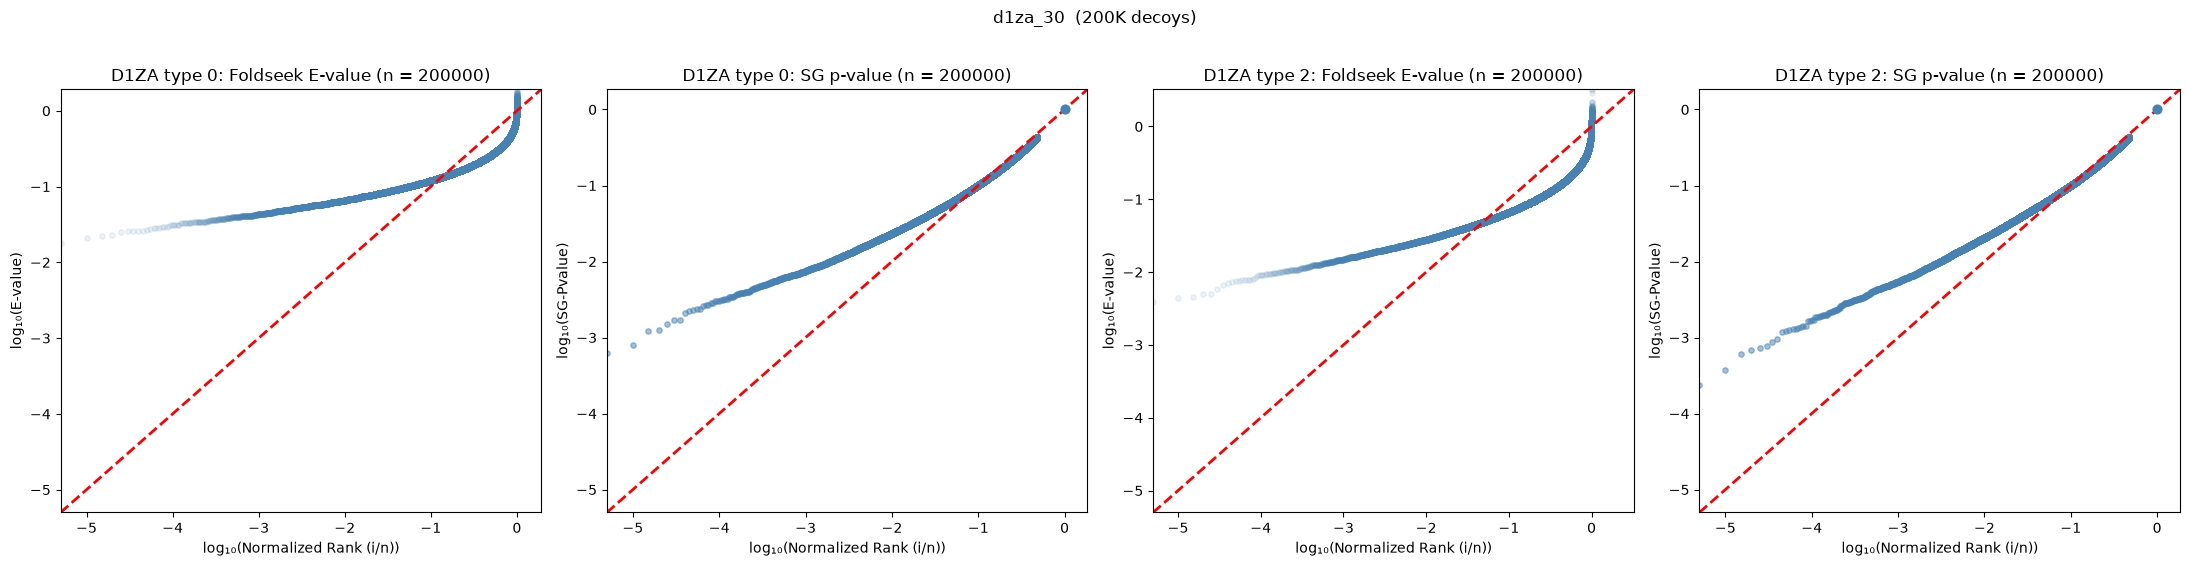

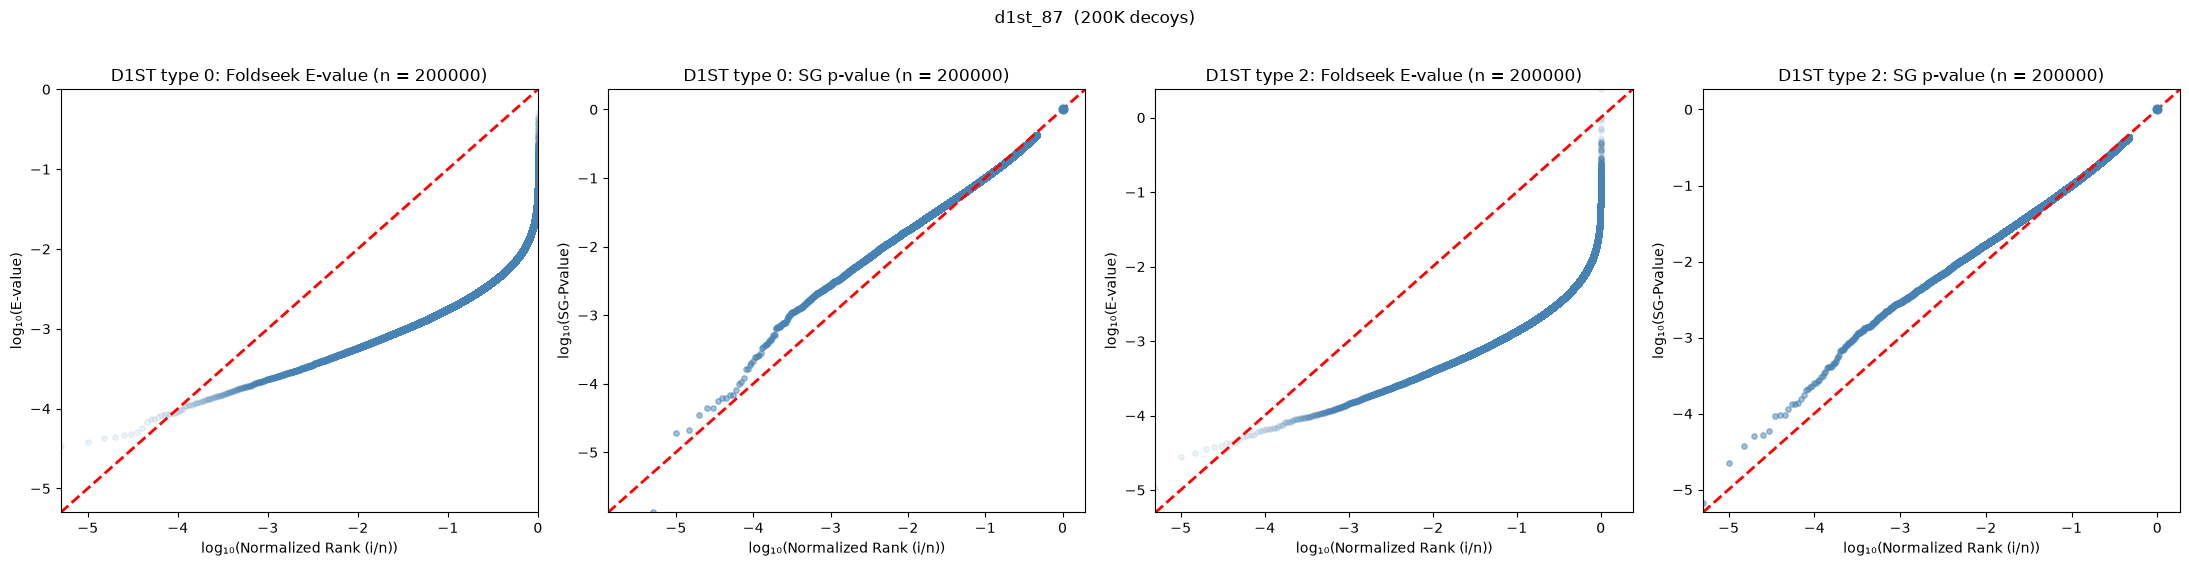

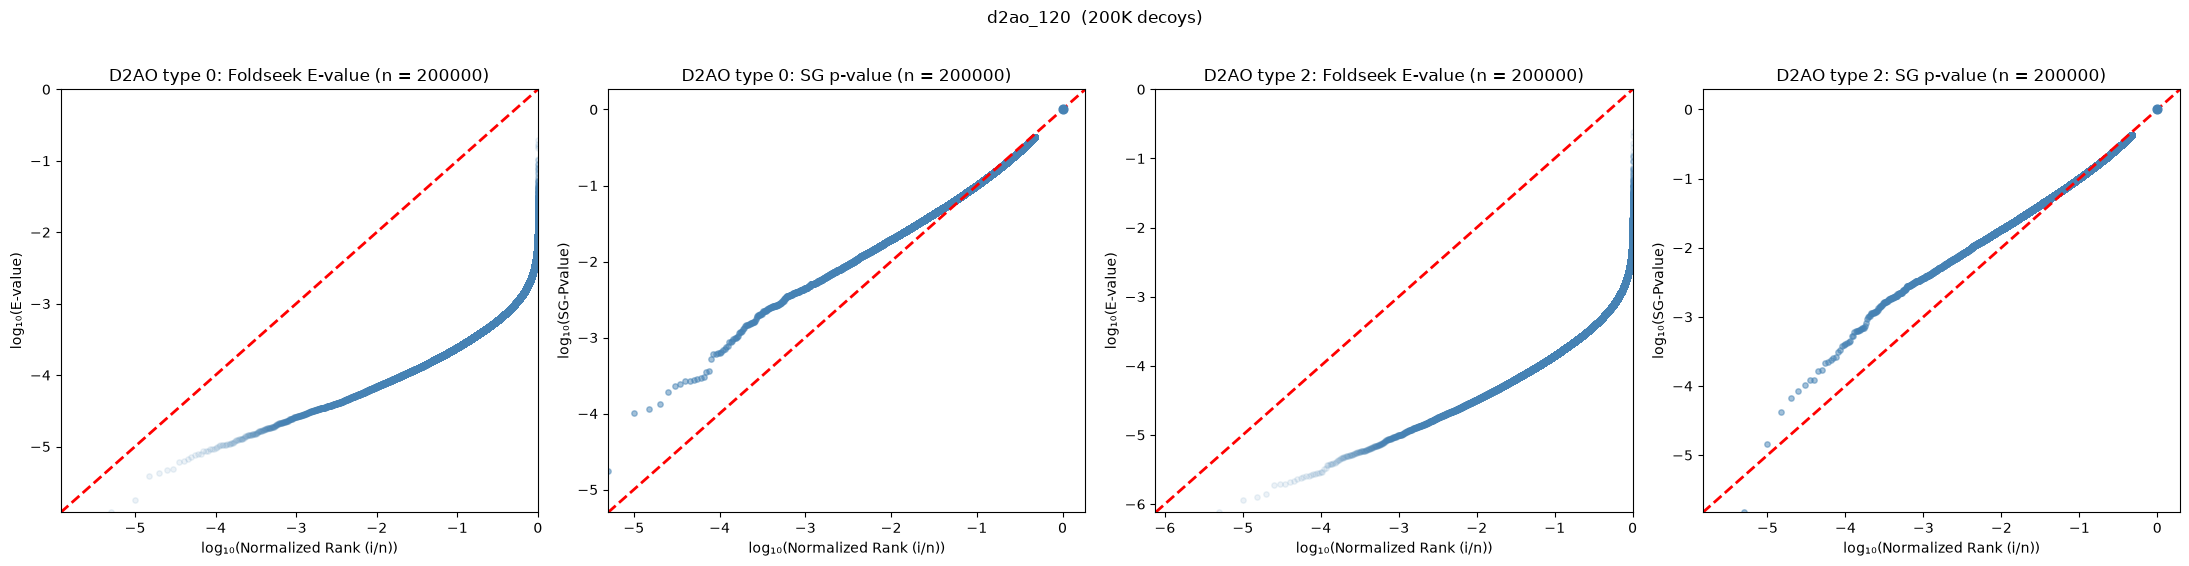

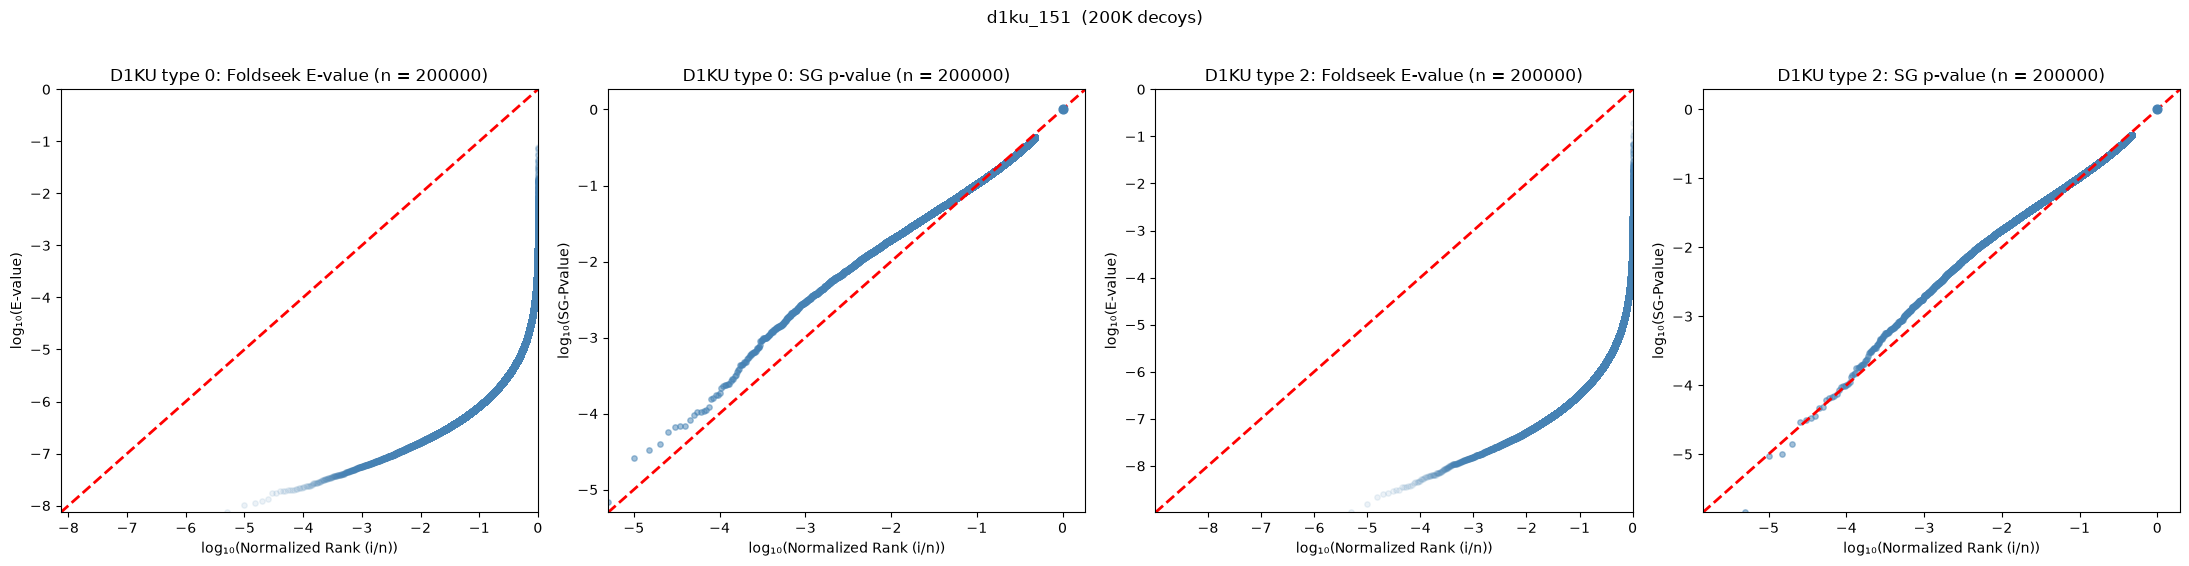

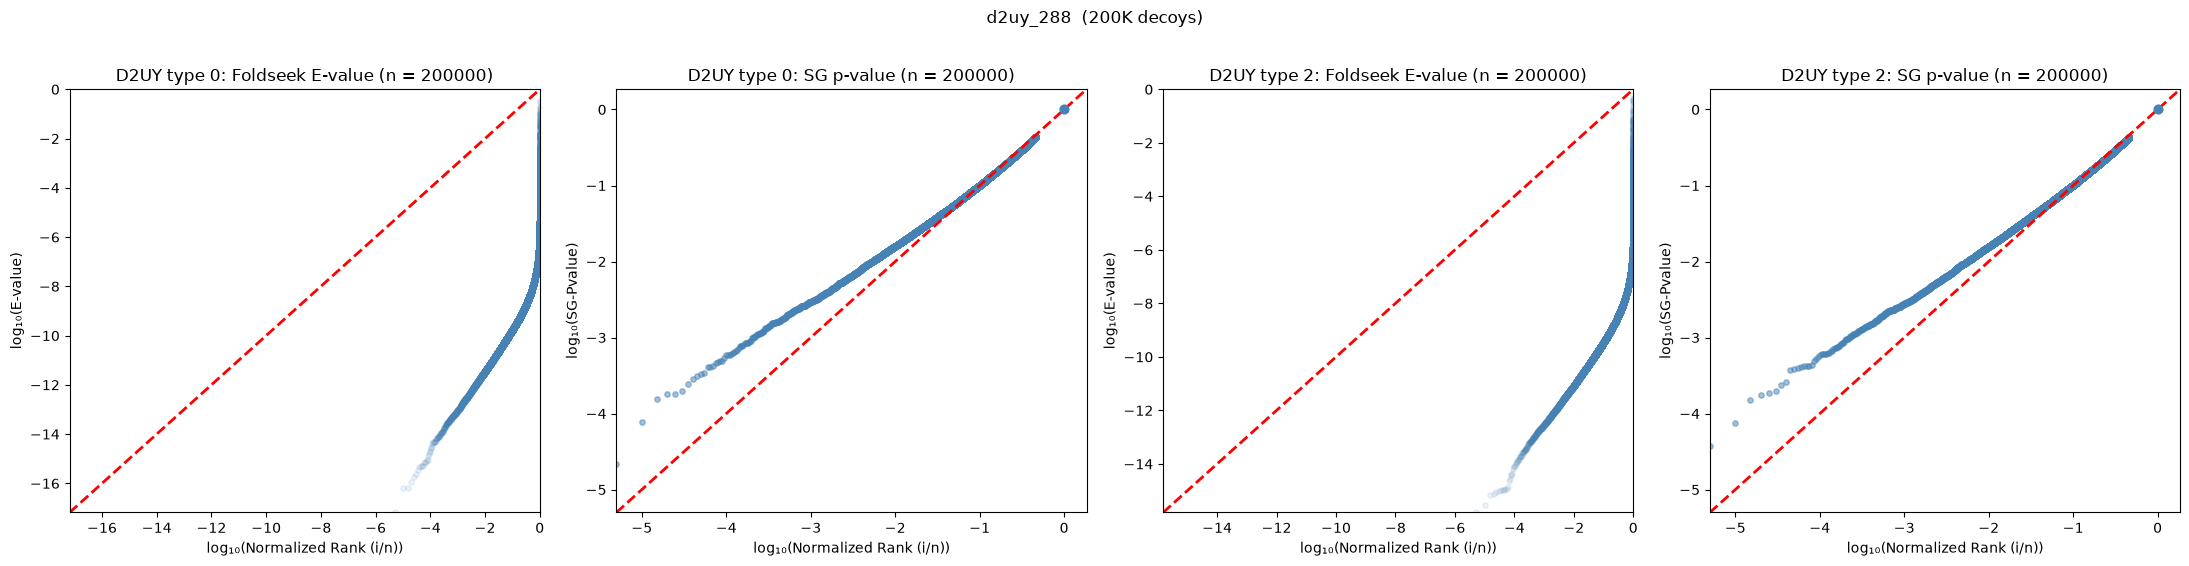

In [10]:
for _, tag, aa_len in QUERIES:
    out = OUTROOT / tag
    name = tag.split('_')[0].upper()
    fig, axes = plt.subplots(1, 2 * len(ALN_TYPES), figsize=(5.5 * 2 * len(ALN_TYPES), 5.5))
    for k, t in enumerate(ALN_TYPES):
        ev = pd.read_csv(out / f'sorted_evalue_{sfx(t)}.tsv', sep='\t')
        sg = pd.read_csv(out / f'sgpvalue_{sfx(t)}.tsv', sep='\t')
        ev_title = f'QQ Plot: E-value vs {n_label(NUM_SHUFFLES)} for {name} (AA: {aa_len}, type {t}) (n = {{n}})'
        sg_title = f'QQ Plot: SG-Pvalue vs {n_label(NUM_SHUFFLES)} for {name} (AA: {aa_len}, type {t}) (n = {{n}})'
        save_qq(draw_qq_evalue, ev, ev_title, out / f'qqplot_Evalue_{sfx(t)}.pdf')
        save_qq(draw_qq_sgpvalue, sg, sg_title, out / f'qqplot_SGPvalue_{sfx(t)}.pdf')
        draw_qq_evalue(axes[2 * k], ev, f'{name} type {t}: Foldseek E-value (n = {{n}})')
        draw_qq_sgpvalue(axes[2 * k + 1], sg, f'{name} type {t}: SG p-value (n = {{n}})')
    fig.suptitle(f'{tag}  ({n_label(NUM_SHUFFLES)} decoys)', y=1.02)
    fig.tight_layout()
    plt.show()